# Lesson 2 — The neural network and how the agent chooses a move

In this lesson you learn:

1. What the network is: layers, weights, and ReLU.
2. How data goes through the network (the **forward pass**). You calculate it by hand.
3. How the agent uses the network to choose a move.
4. How the pre-trained agent of the author plays, and what it learned.
5. How the agent explores (**epsilon-greedy**).

Source file for this lesson: `src/deep_q_network.py`. Do Lesson 1 first.

---

**🇻🇳 Bài 2 — Mạng nơ-ron và cách agent chọn nước đi**

Trong bài này bạn học:

1. Mạng nơ-ron là gì: các lớp (layers), trọng số (weights) và ReLU.
2. Dữ liệu đi qua mạng như thế nào (**forward pass** — lan truyền xuôi). Bạn tự tính bằng tay.
3. Agent dùng mạng để chọn nước đi như thế nào.
4. Agent đã huấn luyện sẵn của tác giả chơi thế nào, và nó đã học được gì.
5. Agent khám phá như thế nào (**epsilon-greedy**).

File mã nguồn của bài này: `src/deep_q_network.py`. Hãy làm Bài 1 trước.

In [1]:
# Setup: find the project folder, so that "import src..." works from this notebook.
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
print("Project folder:", ROOT)

Project folder: /Users/phuonghqh/Documents/working/Tetris-deep-Q-learning-pytorch


In [2]:
import random
import matplotlib.pyplot as plt
import torch
from src.tetris import Tetris
from src.deep_q_network import DeepQNetwork
from src.model_io import load_model
from nb_utils import (afterstates, draw_top_choices, draw_boards, feature_sweep, play_game,
                      evaluate, random_policy, greedy_policy, FEATURE_NAMES)

## Part 1 — The network

```
4 numbers ─► Linear(4→64) ─► ReLU ─► Linear(64→64) ─► ReLU ─► Linear(64→1) ─► 1 number (the value)
```

- **Linear layer:** each output is a weighted sum of all inputs, plus a bias. The weights are the numbers that training changes.
- **ReLU:** the rule `ReLU(x) = max(0, x)`. It changes negative numbers to 0.

> **A common misunderstanding: ReLU is not a move.**
> The network has no "left", "right" or "rotate" output. It has **3 Linear layers and 2 ReLU**
> (after layer 1 and layer 2; the last layer has no ReLU). The game lists every final place `(x, rotation)`.
> The network gives **one value** to the board after each place. The agent takes the place with the highest value.

Note: in the code the layers have the names `conv1`, `conv2`, `conv3`, but they are not convolution layers.

---

**🇻🇳 Phần 1 — Mạng nơ-ron**

Sơ đồ ở trên: 4 con số đi qua 3 lớp Linear và 2 ReLU, và ra 1 con số (giá trị).

- **Lớp Linear (tuyến tính):** mỗi đầu ra là tổng có trọng số của mọi đầu vào, cộng thêm một độ lệch (bias).
  Trọng số là những con số mà quá trình huấn luyện thay đổi.
- **ReLU:** quy tắc `ReLU(x) = max(0, x)`. Nó đổi số âm thành 0.

> **Một hiểu lầm thường gặp: ReLU không phải là một nước đi.**
> Mạng không có đầu ra "trái", "phải" hay "xoay". Mạng có **3 lớp Linear và 2 ReLU**
> (sau lớp 1 và lớp 2; lớp cuối không có ReLU). Trò chơi liệt kê mọi vị trí cuối cùng `(x, rotation)`.
> Mạng cho **một giá trị** cho bàn chơi sau mỗi vị trí. Agent chọn vị trí có giá trị cao nhất.

Lưu ý: trong code các lớp có tên `conv1`, `conv2`, `conv3`, nhưng chúng không phải lớp tích chập (convolution).

In [3]:
torch.manual_seed(0)
model = DeepQNetwork()          # a new network with random weights (untrained)
print(model)
print()
for name, p in model.named_parameters():
    print(f"{name:<16} shape={str(tuple(p.shape)):<10} count={p.numel()}")
print("total weights:", sum(p.numel() for p in model.parameters()))

DeepQNetwork(
  (conv1): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU(inplace=True)
  )
  (conv2): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU(inplace=True)
  )
  (conv3): Sequential(
    (0): Linear(in_features=64, out_features=1, bias=True)
  )
)

conv1.0.weight   shape=(64, 4)    count=256
conv1.0.bias     shape=(64,)      count=64
conv2.0.weight   shape=(64, 64)   count=4096
conv2.0.bias     shape=(64,)      count=64
conv3.0.weight   shape=(1, 64)    count=64
conv3.0.bias     shape=(1,)       count=1
total weights: 4545


### Why ReLU?

Without ReLU, 3 Linear layers act like **1** Linear layer: they can learn only straight-line relations.
ReLU adds a "bend". With many bends, the network can learn curved relations, for example
"1 hole is a small problem, but 5 holes are a very big problem".

---

**🇻🇳 Tại sao cần ReLU?**

Không có ReLU, 3 lớp Linear hoạt động như **1** lớp Linear: chúng chỉ học được quan hệ đường thẳng.
ReLU thêm một "chỗ gập". Với nhiều chỗ gập, mạng học được quan hệ đường cong, ví dụ
"1 lỗ là vấn đề nhỏ, nhưng 5 lỗ là vấn đề rất lớn".

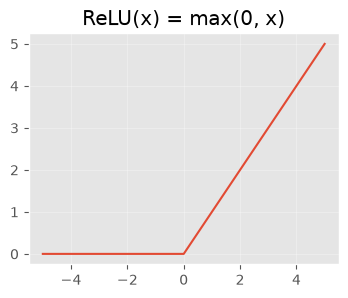

In [4]:
x = torch.linspace(-5, 5, 101)
plt.figure(figsize=(4, 3))
plt.plot(x, torch.relu(x))
plt.title("ReLU(x) = max(0, x)")
plt.grid(alpha=0.3)
plt.show()

## Part 2 — The forward pass, by hand

The **forward pass** is the calculation from the input to the output.
We calculate it with matrix multiplication (`@`) and compare the result with `model(x)`.

---

**🇻🇳 Phần 2 — Lan truyền xuôi (forward pass), tính bằng tay**

**Forward pass** là phép tính từ đầu vào đến đầu ra.
Ta tính nó bằng phép nhân ma trận (`@`) và so sánh kết quả với `model(x)`.

In [5]:
x = torch.tensor([[0., 2., 6., 30.]])      # lines_cleared, holes, bumpiness, height

W1, b1 = model.conv1[0].weight, model.conv1[0].bias
W2, b2 = model.conv2[0].weight, model.conv2[0].bias
W3, b3 = model.conv3[0].weight, model.conv3[0].bias

h1 = torch.relu(x @ W1.T + b1)     # 4 numbers  -> 64 numbers
h2 = torch.relu(h1 @ W2.T + b2)    # 64 numbers -> 64 numbers
out = h2 @ W3.T + b3               # 64 numbers -> 1 number

print("h1 shape:", tuple(h1.shape), "| values that ReLU set to 0:", int((h1 == 0).sum()), "of 64")
print("by hand :", round(out.item(), 5))
print("model(x):", round(model(x).item(), 5))

h1 shape: (1, 64) | values that ReLU set to 0: 34 of 64
by hand : -6.18271
model(x): -6.18271


The network can take many boards at the same time. Each row is one board (a **batch**).
The output has one value per row.

---

🇻🇳 Mạng có thể nhận nhiều bàn chơi cùng lúc. Mỗi hàng là một bàn chơi (một **batch** — lô).
Đầu ra có một giá trị cho mỗi hàng.

In [6]:
batch = torch.tensor([[0., 0., 2., 10.],
                      [1., 0., 4., 20.],
                      [0., 8., 20., 90.]])
print(model(batch))

tensor([[ -2.0076],
        [ -4.2483],
        [-18.6764]], grad_fn=<AddmmBackward0>)


## Part 3 — How the agent chooses a move

1. The game lists all afterstates (Lesson 1).
2. The network gives a value to each one.
3. The agent takes the afterstate with the highest value (`argmax`).

This network is **untrained**: its weights are random. So its choices are random too.

---

**🇻🇳 Phần 3 — Agent chọn nước đi như thế nào**

1. Trò chơi liệt kê mọi afterstate (Bài 1).
2. Mạng cho mỗi afterstate một giá trị.
3. Agent chọn afterstate có giá trị cao nhất (`argmax`).

Mạng này **chưa được huấn luyện**: trọng số của nó là ngẫu nhiên. Vì vậy lựa chọn của nó cũng ngẫu nhiên.

possible actions: 17 - below: the 5 with the highest value (untrained network)


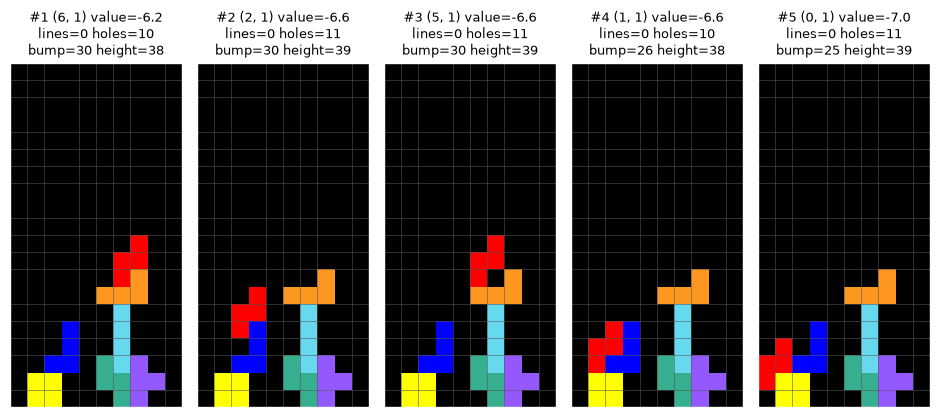

In [7]:
random.seed(7)
env = Tetris()
env.reset()
for _ in range(6):
    env.step(random.choice(list(env.get_next_states())), render=False)
options = afterstates(env)
print("possible actions:", len(options), "- below: the 5 with the highest value (untrained network)")
draw_top_choices(model, options, k=5)

## Part 4 — The pre-trained agent of the author

`trained_models/tetris` holds the network that the author trained. We load it with `load_model()`,
which uses PyTorch **safe mode**. If the file still uses the old PyTorch format, the next cell
prints how to convert it. The rest of the notebook still works without it.

---

**🇻🇳 Phần 4 — Agent đã huấn luyện sẵn của tác giả**

`trained_models/tetris` chứa mạng mà tác giả đã huấn luyện. Ta tải nó bằng `load_model()`,
hàm này dùng **chế độ an toàn** (safe mode) của PyTorch. Nếu file vẫn dùng định dạng PyTorch cũ,
ô tiếp theo in ra cách chuyển đổi. Phần còn lại của notebook vẫn chạy được khi không có nó.

In [9]:
try:
    pretrained = load_model("trained_models/tetris").eval()
    print("Pre-trained model: loaded.")
except RuntimeError as error:
    pretrained = None
    print(error)

Pre-trained model: loaded.


Same board as Part 3. The top 5 choices of the pre-trained network:


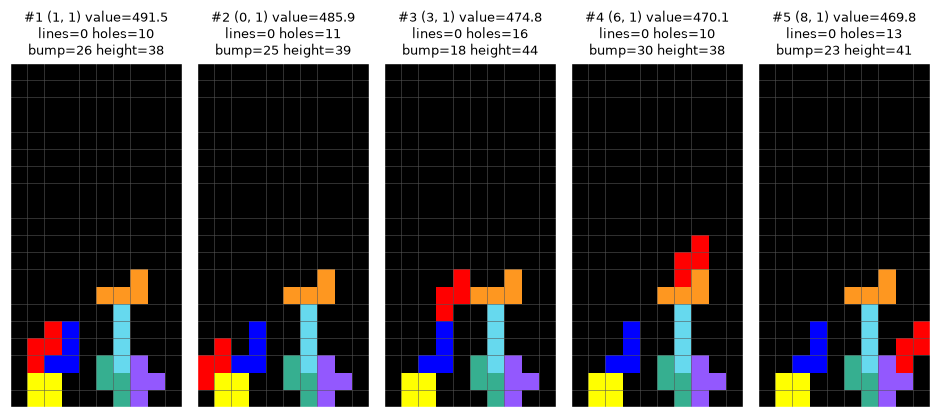

In [10]:
if pretrained is not None:
    print("Same board as Part 3. The top 5 choices of the pre-trained network:")
    draw_top_choices(pretrained, options, k=5)

Now we compare 3 agents. Each plays 3 games, with a limit of 500 pieces per game.

---

🇻🇳 Bây giờ ta so sánh 3 agent. Mỗi agent chơi 3 ván, giới hạn 500 mảnh mỗi ván.

In [11]:
agents = {"random": random_policy, "untrained network": greedy_policy(model)}
if pretrained is not None:
    agents["pre-trained network"] = greedy_policy(pretrained)
for name, policy in agents.items():
    print(f"{name:<20}", evaluate(policy, games=3, max_pieces=500))

random               {'pieces': 20.666666666666668, 'lines': 0.0, 'score': 18.666666666666668}
untrained network    {'pieces': 14.333333333333334, 'lines': 0.0, 'score': 12.333333333333334}
pre-trained network  {'pieces': 358.3333333333333, 'lines': 130.33333333333334, 'score': 2960.3333333333335}


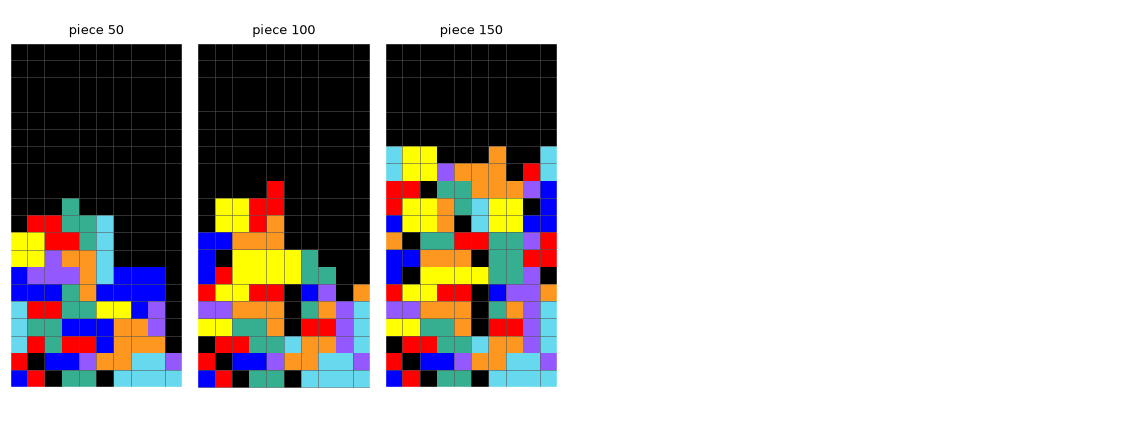

In [12]:
if pretrained is not None:
    game = play_game(greedy_policy(pretrained), max_pieces=300, snapshot_every=50, seed=0)
    boards, titles = zip(*game["snapshots"])
    draw_boards(list(boards), list(titles), cols=6)

To watch a full game in a window, run this in a terminal: `uv run python test.py`.

## Part 5 — What did the network learn?

We change **one** feature and keep the other 3 fixed. Then we plot the network value.
Nobody wrote the rule "holes are bad". If the line goes down when holes go up, the network learned it from rewards.

---

🇻🇳 Để xem trọn một ván trong cửa sổ, chạy lệnh này trong terminal: `uv run python test.py`.

**🇻🇳 Phần 5 — Mạng đã học được gì?**

Ta thay đổi **một** đặc trưng và giữ cố định 3 đặc trưng còn lại. Sau đó ta vẽ giá trị của mạng.
Không ai viết quy tắc "lỗ là xấu". Nếu đường đi xuống khi số lỗ tăng, mạng đã tự học điều đó từ phần thưởng.

In [ ]:
feature_sweep(pretrained if pretrained is not None else model)

**Questions:** Which feature has the strongest effect? Does the value go up with `lines_cleared`?
Run `feature_sweep(model)` for the untrained network and compare.

## Part 6 — Exploration: epsilon-greedy

- **Exploration:** try a random move, to discover new things.
- **Exploitation:** take the best move that the network knows now.
- **Epsilon (ε):** the probability of a random move.

In `train.py`, ε goes down in a straight line from 1.0 to 0.001 over 2000 epochs (1 epoch = 1 game).
At the start the network knows nothing, so random moves collect better experience.

---

🇻🇳 **Câu hỏi:** Đặc trưng nào có ảnh hưởng mạnh nhất? Giá trị có tăng theo `lines_cleared` không?
Chạy `feature_sweep(model)` cho mạng chưa huấn luyện và so sánh.

**🇻🇳 Phần 6 — Khám phá: epsilon-greedy**

- **Khám phá (exploration):** thử một nước đi ngẫu nhiên để tìm ra điều mới.
- **Khai thác (exploitation):** chọn nước đi tốt nhất mà mạng biết hiện tại.
- **Epsilon (ε):** xác suất chọn nước đi ngẫu nhiên.

Trong `train.py`, ε giảm theo đường thẳng từ 1.0 xuống 0.001 trong 2000 epoch (1 epoch = 1 ván).
Lúc đầu mạng chưa biết gì, nên nước đi ngẫu nhiên thu thập được kinh nghiệm tốt hơn.

In [ ]:
initial_epsilon, final_epsilon, num_decay_epochs = 1.0, 1e-3, 2000
epochs = range(3000)
eps = [final_epsilon + max(num_decay_epochs - e, 0) * (initial_epsilon - final_epsilon) / num_decay_epochs
       for e in epochs]
plt.figure(figsize=(5, 3))
plt.plot(epochs, eps)
plt.xlabel("epoch (game)")
plt.ylabel("epsilon")
plt.title("probability of a random move")
plt.grid(alpha=0.3)
plt.show()

for epsilon in (1.0, 0.5, 0.05):
    random_moves = sum(random.random() <= epsilon for _ in range(1000))
    print(f"epsilon={epsilon}: {random_moves} random moves of 1000")

## Summary

- The network: 3 Linear layers, 2 ReLU, about 4,500 weights. Input = 4 numbers, output = 1 value.
- The agent gives a value to each afterstate and takes the highest one.
- A trained network learned that holes, height and bumpiness are bad, from rewards only.
- Epsilon-greedy mixes random moves (exploration) with best moves (exploitation).

### Check your understanding

<details><summary>1. How many ReLU does the network have? Is ReLU a move?</summary>
2 ReLU. No: ReLU is the math rule max(0, x) inside the network. The game lists the moves.
</details>

<details><summary>2. Why does the network output only 1 number, not one number per move?</summary>
It gives a value to a board, not to a move. The agent calls it once for each afterstate.
</details>

<details><summary>3. Why does training start with epsilon = 1.0?</summary>
The untrained network gives random values, so its "best" move means nothing. Random moves give varied experience.
</details>

**Next:** `03_training_loop.ipynb` — train your own network.

---

**🇻🇳 Tóm tắt**

- Mạng: 3 lớp Linear, 2 ReLU, khoảng 4.500 trọng số. Đầu vào = 4 con số, đầu ra = 1 giá trị.
- Agent cho mỗi afterstate một giá trị và chọn cái cao nhất.
- Mạng đã huấn luyện tự học được rằng lỗ, chiều cao và độ gồ ghề là xấu, chỉ từ phần thưởng.
- Epsilon-greedy trộn nước đi ngẫu nhiên (khám phá) với nước đi tốt nhất (khai thác).

**🇻🇳 Kiểm tra hiểu bài**

<details><summary>1. Mạng có bao nhiêu ReLU? ReLU có phải là nước đi không?</summary>
2 ReLU. Không: ReLU là quy tắc toán học max(0, x) bên trong mạng. Trò chơi liệt kê các nước đi.
</details>

<details><summary>2. Tại sao mạng chỉ cho ra 1 con số, mà không phải một số cho mỗi nước đi?</summary>
Mạng cho giá trị cho một bàn chơi, không phải cho một nước đi. Agent gọi mạng một lần cho mỗi afterstate.
</details>

<details><summary>3. Tại sao huấn luyện bắt đầu với epsilon = 1.0?</summary>
Mạng chưa huấn luyện cho giá trị ngẫu nhiên, nên nước đi "tốt nhất" của nó không có ý nghĩa. Nước đi ngẫu nhiên cho kinh nghiệm đa dạng.
</details>

**Tiếp theo:** `03_training_loop.ipynb` — tự huấn luyện mạng của bạn.